In [ ]:
import pandas as pd
import numpy as np

# 1. Load Raw Data & Bed Capacity Lookup
df = pd.read_csv('carewell_raw_data.csv')
df_cap = pd.read_csv('carewell_bed_capacity.csv')

print("Before Cleaning -> Rows:", len(df), "| Duplicates:", df.duplicated(subset=['admission_id']).sum())
print("Missing Values:\n", df.isnull().sum()[df.isnull().sum() > 0])

# 2. Remove duplicate admission_id records
df.drop_duplicates(subset=['admission_id'], keep='first', inplace=True)

# 3. Handle missing values
df['icu_days'] = df['icu_days'].fillna(0.0)
df['age_group'] = df['age_group'].fillna(df['age_group'].mode()[0])
df['claim_status'] = np.where(
    df['claim_status'].isnull(),
    np.where(df['payment_type'] == 'Cash', 'Approved', 'Pending'),
    df['claim_status']
)

# 4. Standardize dates & compute Length of Stay (LOS)
df['admission_date'] = pd.to_datetime(df['admission_date'])
df['discharge_date'] = pd.to_datetime(df['discharge_date'])
df['length_of_stay'] = (df['discharge_date'] - df['admission_date']).dt.days.clip(lower=1)

# 5. Engineer helper columns for EDA, SQL, Excel & Power BI
df['admission_month'] = df['admission_date'].dt.to_period('M').astype(str)
df['month_num'] = df['admission_date'].dt.month
df['season'] = df['month_num'].map({
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Summer', 4: 'Summer', 5: 'Summer', 6: 'Summer',
    7: 'Monsoon', 8: 'Monsoon', 9: 'Monsoon', 10: 'Monsoon', 11: 'Winter'
})
df['revenue_lost'] = np.where(df['claim_status'] == 'Rejected', (df['claim_amount'] - df['amount_received']).round(2), 0.0)
df['is_readmitted_30d'] = np.where(df['readmitted_within_30_days'] == 'Yes', 1, 0)

# Merge department bed capacity
df = df.merge(df_cap, on=['hospital', 'department'], how='left')

print("\nAfter Cleaning -> Rows:", len(df), "| Total Missing Values:", df.isnull().sum().sum())
df.to_csv('carewell_cleaned.csv', index=False)

Before Cleaning -> Rows: 5235 | Duplicates: 35
Missing Values:
 age_group        79
icu_days        159
claim_status     52
dtype: int64

After Cleaning -> Rows: 5200 | Total Missing Values: 0


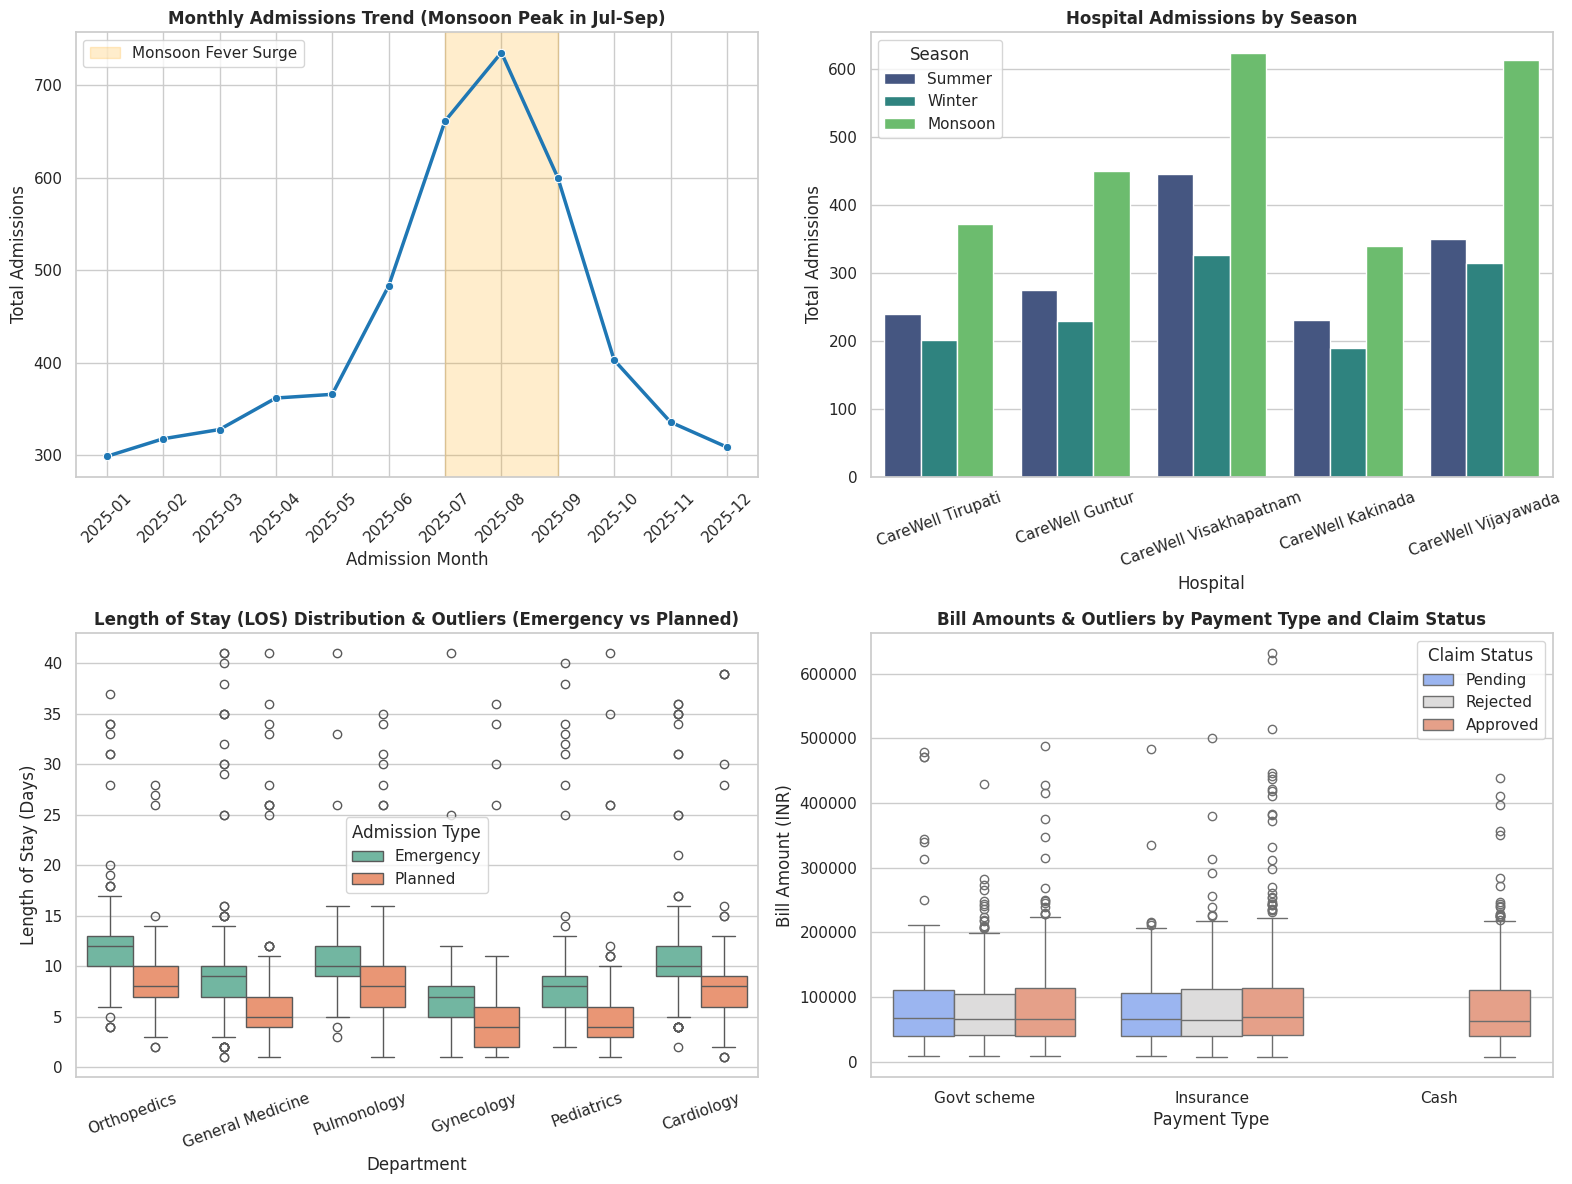

/tmp/ipykernel_1841/510849099.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_docs, x='doctor_id', y='patients', palette='Blues_r', ax=axes2[0])


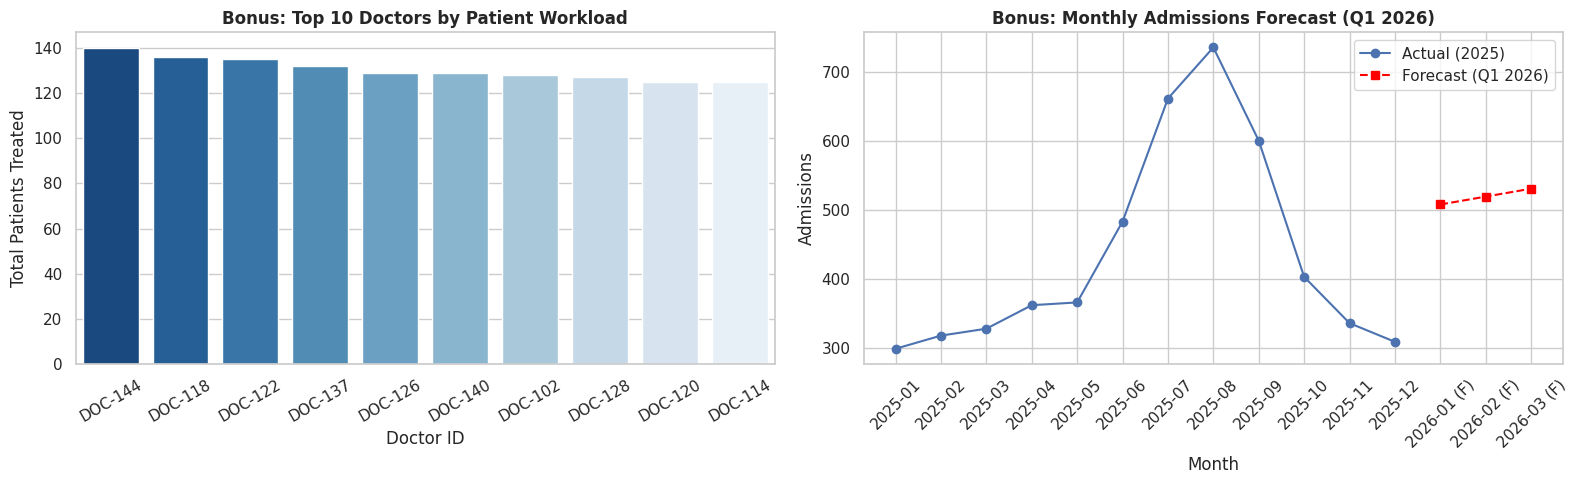

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Chart 1: Monthly Admissions Trend (Highlighting Monsoon Spike)
monthly_adm = df.groupby('admission_month')['admission_id'].count().reset_index()
sns.lineplot(data=monthly_adm, x='admission_month', y='admission_id', marker='o', linewidth=2.5, color='#1f77b4', ax=axes[0, 0])
axes[0, 0].axvspan('2025-07', '2025-09', color='orange', alpha=0.2, label='Monsoon Fever Surge')
axes[0, 0].set_title('Monthly Admissions Trend (Monsoon Peak in Jul-Sep)', fontweight='bold')
axes[0, 0].set_xlabel('Admission Month')
axes[0, 0].set_ylabel('Total Admissions')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].legend()

# Chart 2: Admissions by Hospital and Season
sns.countplot(data=df, x='hospital', hue='season', palette='viridis', ax=axes[0, 1])
axes[0, 1].set_title('Hospital Admissions by Season', fontweight='bold')
axes[0, 1].set_xlabel('Hospital')
axes[0, 1].set_ylabel('Total Admissions')
axes[0, 1].tick_params(axis='x', rotation=20)
axes[0, 1].legend(title='Season')

# Chart 3: Length of Stay (LOS) & Outliers by Admission Type & Department
sns.boxplot(data=df, x='department', y='length_of_stay', hue='admission_type', palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('Length of Stay (LOS) Distribution & Outliers (Emergency vs Planned)', fontweight='bold')
axes[1, 0].set_xlabel('Department')
axes[1, 0].set_ylabel('Length of Stay (Days)')
axes[1, 0].tick_params(axis='x', rotation=20)
axes[1, 0].legend(title='Admission Type')

# Chart 4: Bill Amount Distribution & Outliers by Payment Type
sns.boxplot(data=df, x='payment_type', y='bill_amount', hue='claim_status', palette='coolwarm', ax=axes[1, 1])
axes[1, 1].set_title('Bill Amounts & Outliers by Payment Type and Claim Status', fontweight='bold')
axes[1, 1].set_xlabel('Payment Type')
axes[1, 1].set_ylabel('Bill Amount (INR)')
axes[1, 1].legend(title='Claim Status')

plt.tight_layout()
plt.savefig('EDA_Main_Charts.png', dpi=300)
plt.show()

# ==========================================
# BONUS CHARTS: DOCTOR WORKLOAD & FORECAST
# ==========================================
fig2, axes2 = plt.subplots(1, 2, figsize=(16, 5))

# Bonus 1: Top 10 Busiest Doctors
top_docs = df.groupby('doctor_id').agg(
    patients=('admission_id', 'count'),
    avg_los=('length_of_stay', 'mean')
).sort_values(by='patients', ascending=False).head(10).reset_index()

sns.barplot(data=top_docs, x='doctor_id', y='patients', palette='Blues_r', ax=axes2[0])
axes2[0].set_title('Bonus: Top 10 Doctors by Patient Workload', fontweight='bold')
axes2[0].set_xlabel('Doctor ID')
axes2[0].set_ylabel('Total Patients Treated')
axes2[0].tick_params(axis='x', rotation=30)

# Bonus 2: 3-Month Admissions Forecast (Q1 2026)
monthly_adm['t'] = np.arange(len(monthly_adm))
z = np.polyfit(monthly_adm['t'], monthly_adm['admission_id'], 1)
p = np.poly1d(z)
future_t = np.arange(len(monthly_adm), len(monthly_adm) + 3)
future_months = ['2026-01 (F)', '2026-02 (F)', '2026-03 (F)']
forecast_vals = p(future_t)

axes2[1].plot(monthly_adm['admission_month'], monthly_adm['admission_id'], marker='o', label='Actual (2025)')
axes2[1].plot(future_months, forecast_vals, marker='s', linestyle='--', color='red', label='Forecast (Q1 2026)')
axes2[1].set_title('Bonus: Monthly Admissions Forecast (Q1 2026)', fontweight='bold')
axes2[1].set_xlabel('Month')
axes2[1].set_ylabel('Admissions')
axes2[1].tick_params(axis='x', rotation=45)
axes2[1].legend()

plt.tight_layout()
plt.savefig('EDA_Bonus_Charts.png', dpi=300)
plt.show()